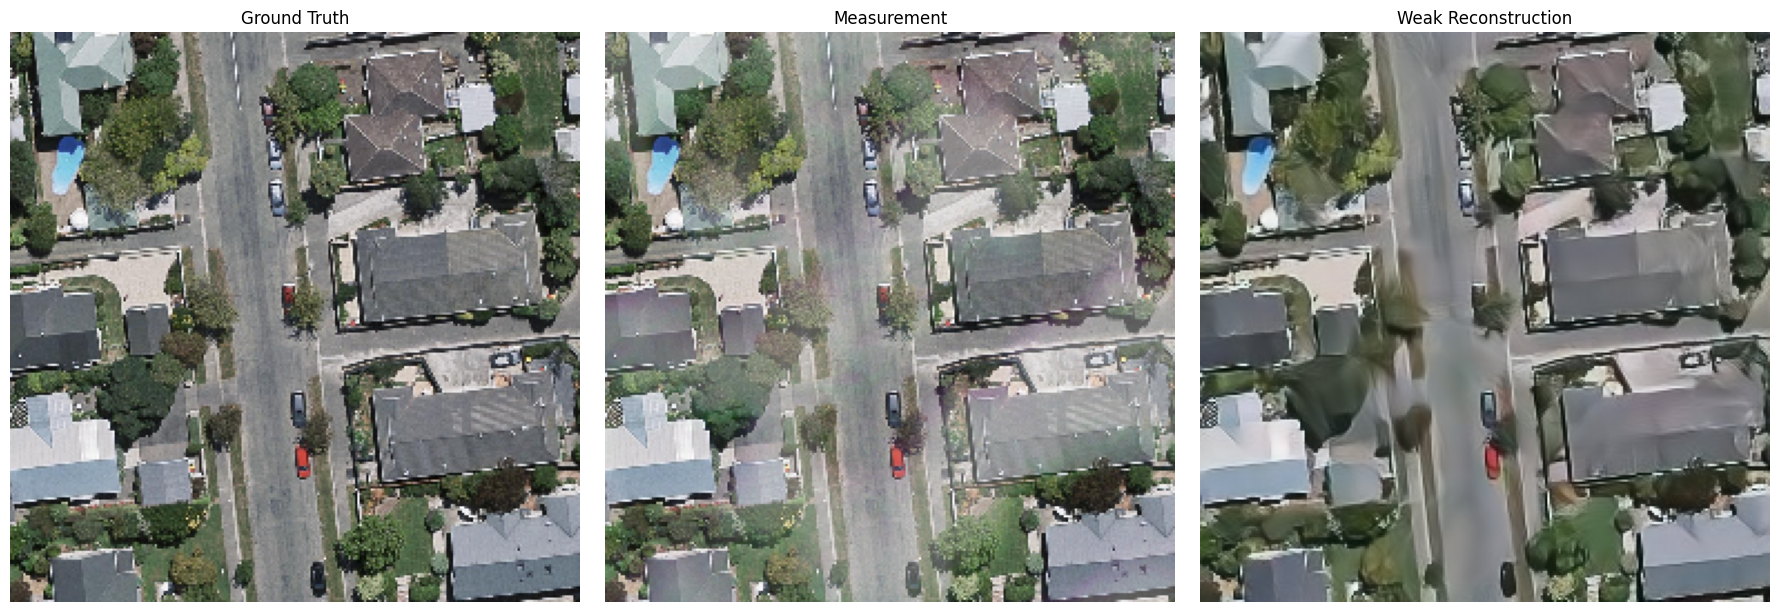

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

stem = "279"  # Change to your image filename
data_dir = Path("../data/whu")#
result_dir = Path("../results/weak_result/celeba/whu/cloud")

# Load images
original = np.array(
    Image.open(data_dir / f"{stem}.png").convert("RGB").resize((256, 256))
) / 255.0

measurement = np.load(result_dir / "measure" / f"{stem}_measure.npy").squeeze()
reconstruction = np.load(result_dir / "recon" / f"{stem}_es_recon.npy").squeeze()

## Convert CHW -> HWC if necessary
reconstruction = reconstruction.transpose(1, 2, 0)
measurement = measurement.transpose(1, 2, 0)

# Metrics
metrics = np.load(result_dir / "recon" / f"{stem}_metrics.npz")
psnr = float(metrics["final_psnr"])
ssim = float(metrics["final_ssim"])
lpips = float(metrics["final_lpips"])

# Plot
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(original)
axes[0].set_title("Ground Truth")

#axes[1].imshow(measurement)
measurement_vis = (measurement + 1.0) / 2.0
measurement_vis = np.clip(measurement_vis, 0, 1)

axes[1].imshow(measurement_vis)
axes[1].set_title("Measurement")

axes[2].imshow(np.clip(reconstruction, 0, 1))
axes[2].set_title("Weak Reconstruction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [4]:
from pathlib import Path
import numpy as np

result_dir = Path("../results/dps_result/celeba/celeba/super")
metrics_dir = result_dir / "recon"
metric_files = sorted(metrics_dir.glob("*_metrics.npz"))

psnr_values = []
ssim_values = []
lpips_values = []

for file in metric_files:
    metrics = np.load(file)

    psnr_values.append(float(metrics["final_psnr"]))
    ssim_values.append(float(metrics["final_ssim"]))
    lpips_values.append(float(metrics["final_lpips"]))

print(f"Number of images: {len(metric_files)}")

print(f"PSNR:  {np.mean(psnr_values):.4f} ± {np.std(psnr_values):.4f}")
print(f"LPIPS: {np.mean(lpips_values):.4f} ± {np.std(lpips_values):.4f}")
print(f"SSIM:  {np.mean(ssim_values):.4f} ± {np.std(ssim_values):.4f}")

Number of images: 100
PSNR:  24.4022 ± 1.7693
LPIPS: 0.3503 ± 0.0474
SSIM:  0.6673 ± 0.0763


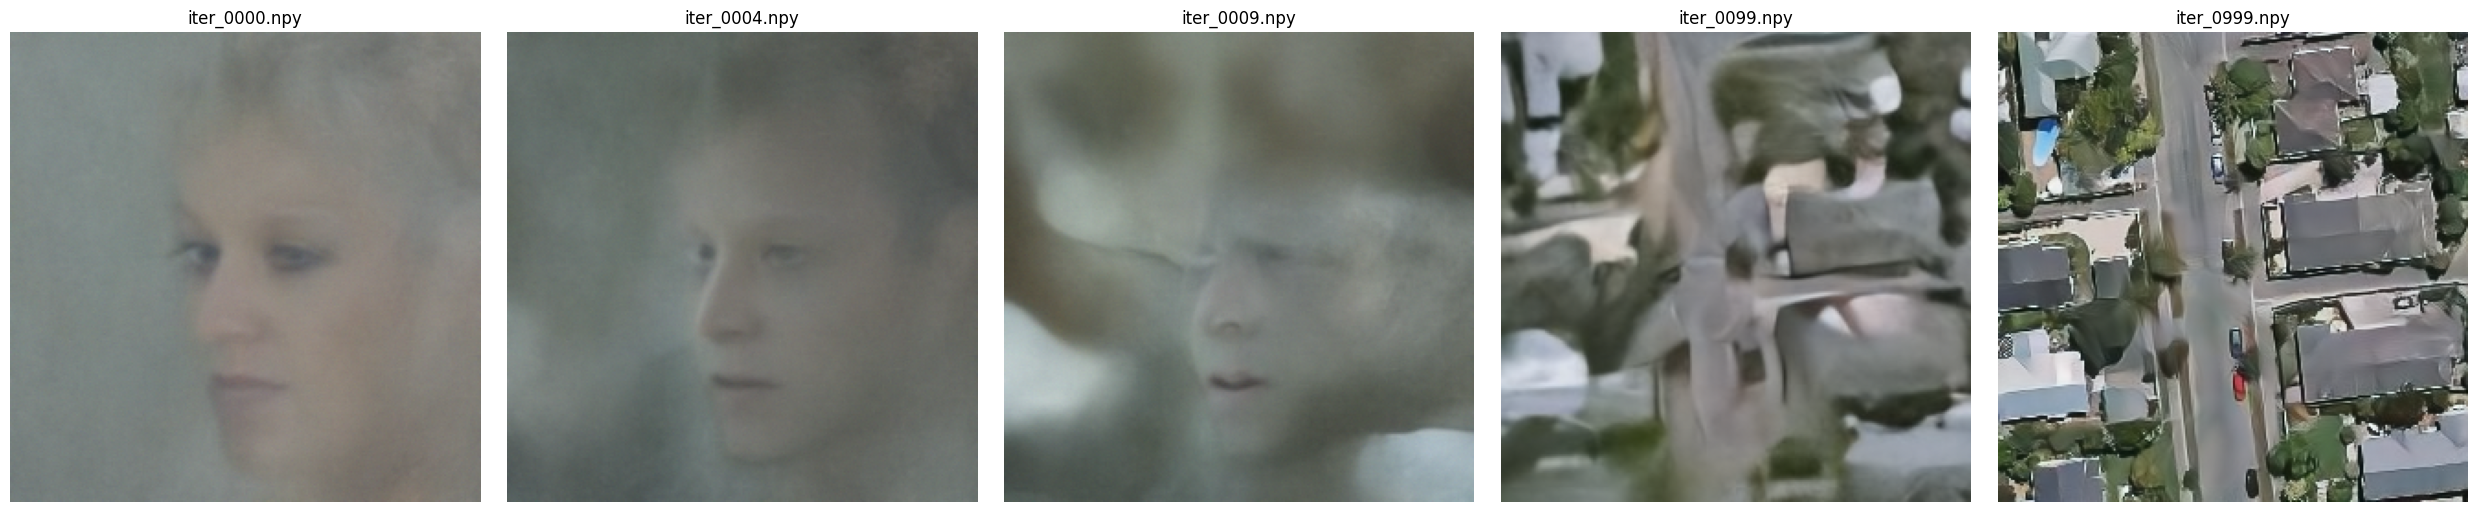

In [30]:

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt


def visualize_npy_images(directory):
    directory = Path(directory)
    files = sorted(directory.glob("*.npy"))

    n_images = len(files)
    fig, axes = plt.subplots(1, n_images, figsize=(5 * n_images, 5))

    # Handle the single-image case
    axes = np.atleast_1d(axes)

    for ax, file in zip(axes, files):
        image = np.load(file).squeeze()

        if image.shape[0] == 3:
            image = image.transpose(1, 2, 0)

        ax.imshow(image[..., :3])
        ax.set_title(file.name)
        ax.axis("off")

    plt.tight_layout()
    plt.show()


visualize_npy_images(
    directory="../results/weak_result/celeba/whu/cloud/process/279"
)

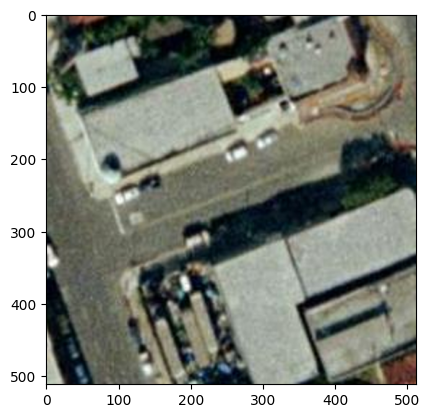

In [ ]:
import satellite_cloud_generator as scg
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

stem = "train_0400"  # Change to your image filename
data_dir = Path("../data/ucmerced/")
image = np.array(
    Image.open(data_dir / f"{stem}.jpg").convert("RGB").resize((512, 512))
) / 255.0
plt.imshow(image)

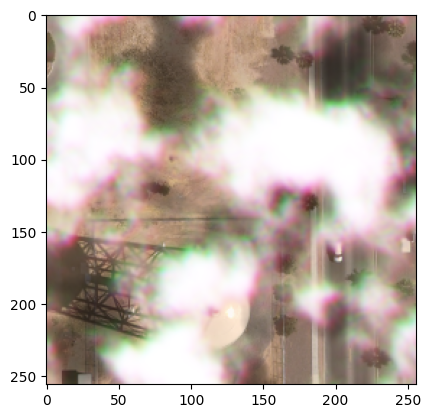

In [45]:
import satellite_cloud_generator as scg
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

stem = "0"  # Change to your image filename
data_dir = Path("../data/ucmerced")
image = np.array(
    Image.open(data_dir / f"{stem}.png").convert("RGB")
) / 255.0
plt.imshow(image)

image = np.transpose(image, (2, 0, 1))  # HWC -> CHW
image = image[None, ...] 
cloudy, mask, shadow = scg.add_cloud_and_shadow(image,
                             min_lvl=0.0,
                             max_lvl=1.0,
                             return_cloud=True
                         )
plt.imshow(np.transpose(cloudy[0], (1, 2, 0)))
#plt.imshow(np.transpose(mask[0], (1, 2, 0)));